# ResNet152 fine-tuned: ImageNet weights → RDN full fine-tuning

This notebook contains its configuration, data checks, model construction, training loop, checkpoint resume, plots, and final test evaluation. It imports installed libraries only; no project helper scripts or external configuration files are needed. The four raw dataset files and published weights remain separate.

**Run one GPU notebook at a time.** To switch from an older notebook, finish or interrupt its current epoch, shut down its kernel, then open this notebook and use **Restart Kernel and Run All Cells**. Completed epochs can resume from the compatible saved run.

**This is a code-organization change.** Architecture, initialization, split, preprocessing, learning rates, and stopping settings are preserved. The earlier ViT convergence problems have not been silently changed. Save notebook edits before starting so code identity can be recorded.

## 1. Imports

Installed packages: PyTorch, torchvision, timm, NumPy, scikit-learn, matplotlib, Pillow, and tqdm.

In [1]:
from __future__ import annotations

import contextlib
import copy
import csv
import hashlib
import importlib.metadata
import json
import math
import os
import platform
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import timm
import torch
from PIL import Image
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm


## 2. Settings

Review paths, epoch limit, patience, batch size, and learning rates here. The backbone and new head both train.

In [2]:
MODEL = 'resnet152'
NOTEBOOK_FILENAME = '05_resnet152_finetuned.ipynb'
# Change these paths if your notebook or dataset is stored elsewhere.
PROJECT_DIR = Path.cwd().parent if Path.cwd().name in ("notebooks", "standalone_notebooks") else Path.cwd()
DATA_ROOT = Path(os.environ.get("RDN_DATA_ROOT", Path.home() / "Desktop" / "training_models"))
WEIGHTS_DIR = Path(os.environ.get("RDN_PRETRAINED_DIR", DATA_ROOT / "pretrained"))
NOTEBOOK_PATH = next((p for p in (
    PROJECT_DIR / "standalone_notebooks" / NOTEBOOK_FILENAME,
    Path.cwd() / NOTEBOOK_FILENAME,
    PROJECT_DIR / NOTEBOOK_FILENAME,
) if p.is_file()), PROJECT_DIR / "standalone_notebooks" / NOTEBOOK_FILENAME)

# None uses the same automatic run name as the original notebook.
# Give a new name when changing the recipe; existing runs are checked strictly.
RUN_NAME = None
RUN_TRAINING = True
RUN_FINAL_TEST = True
REQUIRE_CUDA = True

# Edit the values here. No external configuration file is loaded.
CONFIG = {'seed': 42,
 'max_epochs': 10,
 'early_stopping_patience': 7,
 'minimum_improvement': 0.0,
 'optimizer': 'AdamW',
 'learning_rate': 1e-05,
 'head_learning_rate': 0.0001,
 'weight_decay': 0.05,
 'label_smoothing': 0.0,
 'warmup_epochs': 2,
 'minimum_lr_ratio': 0.01,
 'gradient_clip_norm': 1.0,
 'precision': 'bf16',
 'num_workers': 0,
 'resume': True,
 'image_size': 224,
 'channels': 3,
 'normalization': 'imagenet',
 'interpolation': 'bicubic',
 'train_backbone': True,
 'require_fast_vmamba': True,
 'activation_checkpointing': False,
 'batch_size': 4,
 'accumulation_steps': 32,
 'feature_batch_size': 4,
 'initialization': 'pretrained',
 'model': 'resnet152',
 'architecture': 'resnet152.a1h_in1k',
 'notes': ''}

print(f"{MODEL}: maximum {CONFIG['max_epochs']} epochs, patience {CONFIG['early_stopping_patience']}")
print("Effective batch:", CONFIG["batch_size"] * CONFIG["accumulation_steps"])


resnet152: maximum 10 epochs, patience 7
Effective batch: 128


## 3a. Runtime utilities

Device selection, precision, reproducibility, and atomic saving. Defining these functions does not start training.

In [3]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    temporary.replace(path)


def atomic_checkpoint(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    torch.save(value, temporary)
    temporary.replace(path)


def environment_info(device):
    packages = {}
    for name in ("torch", "torchvision", "timm", "numpy", "scikit-learn",
                 "matplotlib", "Pillow", "safetensors", "mamba-ssm", "triton"):
        try:
            packages[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            packages[name] = None
    return {"python": platform.python_version(), "platform": platform.platform(),
            "packages": packages, "cuda_runtime": torch.version.cuda,
            "device": str(device),
            "gpu": torch.cuda.get_device_name(device) if device.type == "cuda" else None,
            "gpu_memory_bytes": torch.cuda.get_device_properties(device).total_memory
            if device.type == "cuda" else None}


def select_device(require_cuda=True):
    if torch.cuda.is_available():
        device = torch.device("cuda")
        # Perform a tiny CUDA operation to catch wheels without this GPU's support.
        value = torch.ones(1, device=device) + 1
        if value.item() != 2:
            raise RuntimeError("CUDA check failed")
        return device
    if require_cuda:
        raise RuntimeError("CUDA is unavailable. Select the GPU environment/kernel; "
                           "use a CUDA-enabled Python environment. Training has not started.")
    return torch.device("cpu")


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    # VMamba custom kernels may not have deterministic implementations.
    torch.use_deterministic_algorithms(True, warn_only=True)


def precision_context(device, precision):
    if device.type != "cuda" or precision == "fp32":
        return contextlib.nullcontext()
    if precision == "bf16":
        if not torch.cuda.is_bf16_supported():
            raise RuntimeError("BF16 is unsupported on this GPU; set precision='fp32' or 'fp16'.")
        dtype = torch.bfloat16
    elif precision == "fp16":
        dtype = torch.float16
    else:
        raise ValueError("precision must be bf16, fp16, or fp32")
    return torch.autocast(device_type="cuda", dtype=dtype)


## 3b. Check the dataset

Pin the original four file hashes, binary target, and fixed 97,200 / 10,800 / 3,000 split. Both validation classes are retained.

In [4]:
CLASS_NAMES = ["PeakBelow83", "PeakAtOrAbove83"]
EXPECTED_COUNTS = {"train": 97200, "validation": 10800, "test": 3000}
DATA_SHA256 = {'data/full_manifest.csv': '8b70f0ba4d746e9f504dd89ee03984602f725bfa9e3f359a1e82b46a9f2b0652',
 'data/images.npy': '4d9705401d6c2ca8c62da145506d5c2839c8a7285afd098b9c2fd575510df4da',
 'data/labels.npy': '8f58d927ca4199d703f6e8ada05597a86c50d86126c40ff94e878f7e58239638',
 'data/spectra.npy': '87168b2152ee172511a28da89648dec7366dece8e03310f91324a690819f62c9'}

def load_full_data(root):
    """Validate the exact packaged data, fixed target, and full split; no model evaluation."""
    root = Path(root)
    for name in ("data/images.npy", "data/labels.npy", "data/spectra.npy",
                 "data/full_manifest.csv"):
        actual = sha256_file(root / name)
        if actual != DATA_SHA256[name]:
            raise ValueError(f"File differs from the supplied full release: {name}")
    images = np.load(root / "data/images.npy", mmap_mode="r", allow_pickle=False)
    labels = np.load(root / "data/labels.npy", mmap_mode="r", allow_pickle=False)
    spectra = np.load(root / "data/spectra.npy", mmap_mode="r", allow_pickle=False)
    if images.shape != (111000, 16, 16) or labels.shape != (111000,) or spectra.shape != (111000, 128):
        raise ValueError("Expected the full 111,000-layout RDN release, not the pilot collection")
    if not np.isin(images, [0, 1]).all() or not np.isfinite(spectra).all():
        raise ValueError("Invalid image pixels or response values")
    if not np.array_equal(labels, (spectra.argmax(axis=1) >= 83).astype(np.int64)):
        raise ValueError("Labels must use the fixed compact-response cutoff at index 83")
    with (root / "data/full_manifest.csv").open(newline="", encoding="utf-8") as handle:
        rows = list(csv.DictReader(handle))
    if len(rows) != 111000 or [int(r["array_index"]) for r in rows] != list(range(111000)):
        raise ValueError("The full manifest must map every array index exactly once")
    if len({r["sample_id"] for r in rows}) != 111000:
        raise ValueError("Duplicate sample identifiers")
    if len({r["geometry_sha256"] for r in rows}) != 111000:
        raise ValueError("Duplicate geometries require a grouped split")
    partitions = {}
    for split, expected in EXPECTED_COUNTS.items():
        partition = [r for r in rows if r["split"] == split]
        if len(partition) != expected:
            raise ValueError(f"{split}: expected {expected} layouts, got {len(partition)}")
        indices = np.asarray([int(r["array_index"]) for r in partition], dtype=np.int64)
        expected_source = "test" if split == "test" else "train"
        if any(r["source_split"] != expected_source for r in partition):
            raise ValueError("Released test samples cannot enter training or validation")
        if not np.array_equal(labels[indices], np.asarray([int(r["label"]) for r in partition])):
            raise ValueError("Manifest labels disagree with label array")
        if split == "test" and not np.array_equal(indices, np.arange(108000, 111000)):
            raise ValueError("The original 3,000 released test samples must be preserved")
        if split != "test" and (indices >= 108000).any():
            raise ValueError("Test samples found in training/validation")
        partitions[split] = partition
    identity = {name: DATA_SHA256[name]
                for name in ("data/images.npy", "data/labels.npy", "data/spectra.npy",
                             "data/full_manifest.csv")}
    identity["target"] = "compact_response_argmax_ge_83_first_maximum"
    return partitions, identity


## 3c. Images and loaders

Resize the complete geometry, apply the recorded normalization, and build deterministic loaders. Only the training loader shuffles.

In [5]:
class LayoutDataset(Dataset):
    """Native arrays stay on disk; images are resized only when a sample is loaded."""
    def __init__(self, data_dir, rows, image_size, channels, normalization, interpolation="bilinear"):
        self.path = str(Path(data_dir) / "images.npy")
        self.rows = rows
        self.images = None
        self.channels = channels
        operations = [transforms.Resize((image_size, image_size),
                      interpolation={"bilinear": transforms.InterpolationMode.BILINEAR,
                                     "bicubic": transforms.InterpolationMode.BICUBIC}[interpolation]), transforms.ToTensor()]
        if normalization == "half":
            operations.append(transforms.Normalize([0.5] * channels, [0.5] * channels))
        elif normalization == "imagenet":
            if channels != 3:
                raise ValueError("ImageNet normalization requires three channels")
            operations.append(transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]))
        elif normalization != "none":
            raise ValueError(normalization)
        self.transform = transforms.Compose(operations)

    def __len__(self):
        return len(self.rows)

    def __getstate__(self):
        state = self.__dict__.copy()
        state["images"] = None  # Windows/WSL workers reopen the memory map.
        return state

    def __getitem__(self, index):
        if self.images is None:
            self.images = np.load(self.path, mmap_mode="r", allow_pickle=False)
        row = self.rows[index]
        image = Image.fromarray(self.images[int(row["array_index"])] * np.uint8(255))
        if self.channels == 3:
            image = image.convert("RGB")
        return self.transform(image), int(row["label"]), row["sample_id"]


def seed_worker(worker_id):
    seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(seed)
    random.seed(seed)


def make_loader(dataset, batch_size, shuffle, seed, workers, device):
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      num_workers=workers, pin_memory=device.type == "cuda",
                      persistent_workers=False, worker_init_fn=seed_worker,
                      generator=torch.Generator().manual_seed(seed), drop_last=False)


def layout_dataset(root, rows, config):
    return LayoutDataset(Path(root) / "data", rows, config["image_size"],
                         config["channels"], config["normalization"], config.get("interpolation", "bilinear"))

def build_training_loaders(model, root, partitions, config, device, identity):
    # Recompute the backbone on every step: this is full fine-tuning.
    datasets = {
        split: layout_dataset(root, partitions[split], config)
        for split in ("train", "validation")
    }
    model.to(device)
    loaders = {
        split: make_loader(
            datasets[split], config["batch_size"], split == "train",
            config["seed"], config["num_workers"], device,
        )
        for split in ("train", "validation")
    }
    return model, loaders, False


## 4. Model and ImageNet weights

Architecture: `resnet152.a1h_in1k`. timm constructs the standard backbone; the two-class classifier is new. All parameters train. Resume loads your saved weights instead of downloading again.

In [6]:
def state_digest(model):
    """Record the exact initial tensors, including the seeded two-class head."""
    digest = hashlib.sha256()
    for name, tensor in sorted(model.state_dict().items()):
        digest.update((name + str(tensor.dtype) + str(tuple(tensor.shape))).encode())
        values = tensor.detach().cpu().contiguous().reshape(-1).view(torch.uint8)
        digest.update(values.numpy().tobytes())
    return digest.hexdigest()

def build_model(config, *, load_weights=True, weights_dir=None):
    # timm supplies the standard architecture and published ImageNet weights.
    # num_classes=2 replaces the original classifier with a new task head.
    options = {"pretrained": load_weights, "num_classes": 2}
    if config["architecture"].startswith("vit_"):
        options.update(img_size=config["image_size"], drop_rate=0.1)
    model = timm.create_model(config["architecture"], **options)
    if config["activation_checkpointing"] and hasattr(model, "set_grad_checkpointing"):
        model.set_grad_checkpointing(True)
    model.requires_grad_(True)
    provenance = {"source": "timm/" + config["architecture"]}
    if load_weights:
        provenance["initial_state_sha256"] = state_digest(model)
    return model, provenance


## 5. Optimizer and schedule

AdamW uses separate backbone/head learning rates, excludes bias/norm/token embeddings from decay, warms up for two epochs, and then applies cosine decay.

In [7]:
def classifier_parameters(model):
    if hasattr(model, "head"):
        return model.head.parameters()
    return model.get_classifier().parameters()

def optimizer_and_scheduler(model, config):
    head_ids = {id(p) for p in classifier_parameters(model)}
    groups = {}
    for name, parameter in model.named_parameters():
        if not parameter.requires_grad:
            continue
        head = id(parameter) in head_ids
        no_decay = parameter.ndim <= 1 or any(s in name for s in
                   ("pos_embed", "position_embedding", "class_token", "cls_token"))
        group_name = ("head" if head else "backbone") + ("_no_decay" if no_decay else "_decay")
        group = groups.setdefault(group_name, {"params": [], "name": group_name,
                    "lr": config["head_learning_rate"] if head else config["learning_rate"],
                    "weight_decay": 0.0 if no_decay else config["weight_decay"]})
        group["params"].append(parameter)
    if not groups:
        raise ValueError("No trainable parameters")
    optimizer = torch.optim.AdamW(list(groups.values()))
    warmup, epochs, minimum = config["warmup_epochs"], config["max_epochs"], config["minimum_lr_ratio"]
    def multiplier(epoch):
        if warmup and epoch < warmup:
            return (epoch + 1) / warmup
        progress = min(1.0, max(0.0, (epoch - warmup) / max(1, epochs - warmup - 1)))
        return minimum + (1 - minimum) * (1 + math.cos(math.pi * progress)) / 2
    return optimizer, torch.optim.lr_scheduler.LambdaLR(optimizer, multiplier)


## 6a. One training epoch

Accumulate sample-weighted gradients to the effective batch size. Clip gradients and stop on non-finite loss.

In [8]:
def train_one_epoch(model, loader, optimizer, scaler, config, device):
    """Accumulate sample-weighted gradients, including the smaller final batch/window."""
    model.train()
    optimizer.zero_grad(set_to_none=True)
    criterion = nn.CrossEntropyLoss(label_smoothing=config["label_smoothing"], reduction="sum")
    total_loss = total_correct = total_samples = window_samples = 0
    for step, (images, labels, _) in enumerate(tqdm(loader, desc="Training", leave=False)):
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with precision_context(device, config["precision"]):
            logits = model(images)
            loss_sum = criterion(logits, labels)
        if not torch.isfinite(loss_sum):
            raise FloatingPointError("Non-finite training loss; no checkpoint overwritten")
        # Normalize by a fixed reference batch first, then correct for the actual
        # sample count at the update. This avoids very large FP16 scaled sums.
        scaler.scale(loss_sum / config["batch_size"]).backward()
        samples = len(labels)
        window_samples += samples
        total_samples += samples
        total_loss += loss_sum.detach().item()
        total_correct += (logits.argmax(1) == labels).sum().item()
        update = (step + 1) % config["accumulation_steps"] == 0 or step + 1 == len(loader)
        if update:
            scaler.unscale_(optimizer)
            for parameter in model.parameters():
                if parameter.grad is not None:
                    parameter.grad.mul_(config["batch_size"] / window_samples)
            if config["gradient_clip_norm"]:
                nn.utils.clip_grad_norm_(model.parameters(), config["gradient_clip_norm"],
                                         error_if_nonfinite=config["precision"] != "fp16")
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            window_samples = 0
    return {"loss": total_loss / total_samples, "accuracy": total_correct / total_samples}


## 6b. Validation metrics

Evaluation mode disables dropout. Log loss, accuracy, balanced accuracy, F1, AUC, confusion matrix, and prediction counts; one-class predictions remain visible.

In [9]:
@torch.inference_mode()
def evaluate(model, loader, device, config):
    """Evaluation-mode metrics use unsmoothed cross entropy for every model."""
    model.eval()
    total_loss = total_samples = 0
    labels_all, probabilities_all, predictions_all, sample_ids = [], [], [], []
    for images, labels, ids in tqdm(loader, desc="Evaluation", leave=False):
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with precision_context(device, config["precision"]):
            logits = model(images)
        loss = nn.functional.cross_entropy(logits.float(), labels, reduction="sum")
        probabilities = logits.float().softmax(1)[:, 1]
        if not torch.isfinite(loss) or not torch.isfinite(probabilities).all():
            raise FloatingPointError("Non-finite evaluation output")
        total_loss += loss.item()
        total_samples += len(labels)
        labels_all.extend(labels.cpu().tolist())
        probabilities_all.extend(probabilities.cpu().tolist())
        predictions_all.extend(logits.argmax(1).cpu().tolist())
        sample_ids.extend(ids)
    y = np.asarray(labels_all, dtype=np.int64)
    probability = np.asarray(probabilities_all)
    predicted = np.asarray(predictions_all, dtype=np.int64)  # argmax ties choose class zero.
    metrics = {"records": total_samples, "loss": total_loss / total_samples,
               "accuracy": float(accuracy_score(y, predicted)),
               "balanced_accuracy": float(balanced_accuracy_score(y, predicted)),
               "macro_f1": float(f1_score(y, predicted, average="macro", zero_division=0)),
               "roc_auc": float(roc_auc_score(y, probability)) if len(np.unique(y)) == 2 else None,
               "confusion_matrix": confusion_matrix(y, predicted, labels=[0, 1]).tolist(),
               "prediction_counts": np.bincount(predicted, minlength=2).tolist(),
               "single_class_predictions": bool(len(np.unique(predicted)) == 1),
               "classification_report": classification_report(y, predicted, labels=[0, 1],
                   target_names=CLASS_NAMES, output_dict=True, zero_division=0)}
    return metrics, {"sample_id": sample_ids, "label": y.tolist(),
                     "probability_class_1": probability.tolist(), "prediction": predicted.tolist()}


## 7a. Save results and plot learning curves

Training/validation accuracy and loss are plotted per epoch. The held-out test is evaluated after selecting the checkpoint by validation loss.

In [10]:
def save_predictions(path, predictions):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    with temporary.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.writer(handle)
        columns = list(predictions)
        writer.writerow(columns)
        writer.writerows(zip(*(predictions[c] for c in columns)))
    temporary.replace(path)


def save_history(folder, history):
    atomic_json(Path(folder) / "history.json", history)
    temporary = Path(folder) / "history.csv.tmp"
    with temporary.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)
    temporary.replace(Path(folder) / "history.csv")
    plot_history(folder, history)


def plot_history(folder, history=None, show=False, export_pdf=False):
    folder = Path(folder)
    if history is None:
        history = json.loads((folder / "history.json").read_text())
    epochs = [r["epoch"] for r in history]
    for metric, label, scale in (("accuracy", "Accuracy (%)", 100), ("loss", "Cross-entropy loss", 1)):
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(epochs, [scale * r[f"train_{metric}"] for r in history], label="Training (online)")
        ax.plot(epochs, [scale * r[f"validation_{metric}"] for r in history], label="Validation (evaluation mode)")
        ax.set(xlabel="Epoch", ylabel=label)
        if metric == "accuracy":
            ax.set_ylim(0, 100)
        ax.grid(alpha=0.25)
        ax.legend()
        fig.tight_layout()
        fig.savefig(folder / f"{metric}_curves.png", dpi=180)
        if export_pdf:
            fig.savefig(folder / f"{metric}_curves.pdf")
        if show:
            plt.show()
        plt.close(fig)


## 7b. Checkpoints and resume identity

Save optimizer, scheduler, scaler, RNG, and loader state. Changed settings or implementation require a new run name. Compatible existing runs retain their original contract and record the notebook execution separately.

In [11]:
def capture_rng(loader):
    numpy_state = np.random.get_state()
    return {"python": random.getstate(),
            "numpy": {"algorithm": numpy_state[0], "keys": numpy_state[1].tolist(),
                      "position": numpy_state[2], "has_gauss": numpy_state[3],
                      "cached_gaussian": numpy_state[4]},
            "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
            "loader": loader.generator.get_state()}


def restore_rng(state, loader):
    random.setstate(state["python"])
    values = state["numpy"]
    np.random.set_state((values["algorithm"], np.asarray(values["keys"], dtype=np.uint32),
                         values["position"], values["has_gauss"], values["cached_gaussian"]))
    torch.set_rng_state(state["torch"].cpu())
    if torch.cuda.is_available() and state["cuda"]:
        torch.cuda.set_rng_state_all([x.cpu() for x in state["cuda"]])
    loader.generator.set_state(state["loader"].cpu())


def config_identity(config, identity):
    # Paths may change when the package moves between computers; run meaning must not.
    return {"config": config, "data": identity}


def notebook_program_identity(folder, config, data_identity):
    """Bind new runs to notebook code; safely continue unchanged older runs.

    Output cells and editable settings do not enter the program hash. Settings
    and exact data hashes are checked separately in every checkpoint contract.
    """
    notebook = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
    excluded = {"configuration", "training_launch", "results", "preflight"}
    implementation = [
        [cell["metadata"]["lab_role"], "".join(cell["source"])]
        for cell in notebook["cells"]
        if cell["cell_type"] == "code" and cell["metadata"]["lab_role"] not in excluded
    ]
    digest = hashlib.sha256(json.dumps(implementation).encode()).hexdigest()
    identity = {**data_identity, "notebook_code_sha256": digest}
    previous_path = folder / "run_config.json"
    if not previous_path.exists():
        return identity

    previous = json.loads(previous_path.read_text())
    if previous["config"] != config:
        raise ValueError("Saved settings differ. Choose a new RUN_NAME for changed settings.")
    saved = previous["data"]
    if "notebook_code_sha256" in saved:
        if saved != identity:
            raise ValueError("Notebook code or data changed. Choose a new RUN_NAME.")
        return identity

    # An existing run may predate the self-contained notebooks. Accept its
    # original contract only for the exact implementation verified at release.
    compatibility = notebook["metadata"]["standalone"]
    original_data = {key: value for key, value in saved.items()
                     if key not in ("support_code_sha256", "model_configs_sha256")}
    source_digests = sorted(saved.get("support_code_sha256", {}).values())
    if (digest != compatibility["verified_legacy_code_sha256"]
            or source_digests != compatibility["legacy_source_digests"]
            or saved.get("model_configs_sha256") != compatibility["legacy_config_digest"]
            or original_data != data_identity):
        raise ValueError("Older run is not compatible with this notebook. Choose a new RUN_NAME.")
    record = folder / "notebook_execution.json"
    if record.exists() and json.loads(record.read_text())["notebook_code_sha256"] != digest:
        raise ValueError("This run previously used different notebook code. Choose a new RUN_NAME.")
    atomic_json(record, {"notebook_code_sha256": digest,
                         "notebook": NOTEBOOK_PATH.name,
                         "continuing_original_checkpoint_contract": True})
    print("Using the compatible existing run; notebook execution identity recorded.")
    return saved


## 8. Training loop and early stopping

Select the lowest-validation-loss checkpoint. Stop at the maximum epoch count or after the configured patience. An interrupted partial epoch repeats on resume.

In [12]:
def fit(model, loaders, config, device, folder, identity, model_info):
    """Train/validate only; restore the minimum-validation-loss checkpoint on completion."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    contract = config_identity(config, identity)
    contract_path = folder / "run_config.json"
    if contract_path.exists() and json.loads(contract_path.read_text()) != contract:
        raise ValueError("This run folder has different settings/data. Use another run_name.")
    atomic_json(contract_path, contract)
    atomic_json(folder / "environment.json", environment_info(device))
    atomic_json(folder / "model_info.json", model_info)
    latest, best = folder / "last_checkpoint.pt", folder / "best_checkpoint.pt"
    if (folder / "TRAINING_COMPLETE.json").exists():
        state = torch.load(best, map_location="cpu", weights_only=True)
        if state["contract"] != contract:
            raise ValueError("Completed checkpoint identity mismatch")
        model.load_state_dict(state["model"])
        print("Training already complete; loaded the validation-selected checkpoint.")
        return json.loads((folder / "history.json").read_text())
    optimizer, scheduler = optimizer_and_scheduler(model, config)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda" and config["precision"] == "fp16")
    history, start, best_loss, best_epoch, stale = [], 0, float("inf"), 0, 0
    elapsed_before = 0.0
    if latest.exists():
        if not config["resume"]:
            raise ValueError("Existing checkpoint found. Enable resume or use another run_name.")
        state = torch.load(latest, map_location="cpu", weights_only=True)
        if state["contract"] != contract:
            raise ValueError("Resume checkpoint identity mismatch")
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"])
        scaler.load_state_dict(state["scaler"])
        history, start = state["history"], state["epoch"]
        best_loss, best_epoch, stale = state["best_loss"], state["best_epoch"], state["stale_epochs"]
        elapsed_before = state["training_seconds"]
        restore_rng(state["rng"], loaders["train"])
        print(f"Resuming after epoch {start}; interrupted partial epochs are repeated.")
    started = time.monotonic()
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    for epoch in range(start, config["max_epochs"]):
        if stale >= config["early_stopping_patience"]:
            break
        epoch_start = time.monotonic()
        lr = optimizer.param_groups[0]["lr"]
        training = train_one_epoch(model, loaders["train"], optimizer, scaler, config, device)
        validation, _ = evaluate(model, loaders["validation"], device, config)
        if validation["single_class_predictions"]:
            print("WARNING: validation predictions contain only one class:", validation["prediction_counts"])
        scheduler.step()
        history.append({"epoch": epoch + 1, "learning_rate": lr,
                        "train_loss": training["loss"], "train_accuracy": training["accuracy"],
                        "validation_loss": validation["loss"], "validation_accuracy": validation["accuracy"],
                        "validation_balanced_accuracy": validation["balanced_accuracy"],
                        "validation_macro_f1": validation["macro_f1"],
                        "validation_class0_predictions": validation["prediction_counts"][0],
                        "validation_class1_predictions": validation["prediction_counts"][1],
                        "epoch_seconds": time.monotonic() - epoch_start})
        improved = validation["loss"] < best_loss - config["minimum_improvement"]
        if improved:
            best_loss, best_epoch, stale = validation["loss"], epoch + 1, 0
        else:
            stale += 1
        state = {"contract": contract, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                 "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                 "epoch": epoch + 1, "history": history, "best_loss": best_loss,
                 "best_epoch": best_epoch, "stale_epochs": stale,
                 "training_seconds": elapsed_before + time.monotonic() - started,
                 "rng": capture_rng(loaders["train"])}
        if improved:
            atomic_checkpoint(best, {"contract": contract, "model": model.state_dict(),
                                     "epoch": best_epoch, "validation_loss": best_loss})
        atomic_checkpoint(latest, state)
        save_history(folder, history)
        print(f"Epoch {epoch + 1:03d}: training {training['accuracy']:.2%}; "
              f"validation {validation['accuracy']:.2%}; val loss {validation['loss']:.5f}")
    if not best.exists():
        raise RuntimeError("No validation-selected checkpoint was created")
    selected = torch.load(best, map_location="cpu", weights_only=True)
    model.load_state_dict(selected["model"])
    # Evaluate BOTH train and validation at the SAME selected checkpoint in eval mode.
    summary = {"selection": "minimum_validation_loss", "selected_epoch": selected["epoch"],
               "epochs_completed": len(history), "model_info": model_info,
               "training_seconds": elapsed_before + time.monotonic() - started,
               "peak_gpu_memory_bytes": torch.cuda.max_memory_allocated(device)
               if device.type == "cuda" else None,
               "test_evaluated": False}
    for split in ("train", "validation"):
        original_loader = loaders[split]
        ordered = make_loader(original_loader.dataset, config["batch_size"], False,
                               config["seed"], config["num_workers"], device)
        metrics, predictions = evaluate(model, ordered, device, config)
        summary[split] = metrics
        save_predictions(folder / f"{split}_predictions.csv", predictions)
    atomic_json(folder / "training_validation_metrics.json", summary)
    atomic_json(folder / "TRAINING_COMPLETE.json", {"selected_epoch": selected["epoch"],
                                                  "epochs_completed": len(history), "test_evaluated": False})
    return history


## 9. Final held-out test

Evaluate the validation-selected checkpoint once and reuse its recorded test result. Save predictions, metrics, and the test confusion matrix.

In [13]:
def evaluate_test(model, training_model, root, partitions, config, device, folder, identity, cached):
    """An explicitly called, cached final test evaluation. Never called by fit()."""
    folder = Path(folder)
    if not (folder / "TRAINING_COMPLETE.json").exists():
        raise RuntimeError("Complete training/validation selection before evaluating the test set")
    checkpoint = folder / "best_checkpoint.pt"
    checksum = sha256_file(checkpoint)
    state = torch.load(checkpoint, map_location="cpu", weights_only=True)
    if state["contract"] != config_identity(config, identity):
        raise ValueError("Test checkpoint identity mismatch")
    output = folder / "test_metrics.json"
    if output.exists():
        stored = json.loads(output.read_text())
        if stored["checkpoint_sha256"] != checksum:
            raise ValueError("Test output exists for a different checkpoint; refusing to overwrite it")
        print("Using the existing final test evaluation.")
        return stored
    training_model.load_state_dict(state["model"])
    training_model.to(device)
    rows = partitions["test"]
    dataset = layout_dataset(root, rows, config)
    loader = make_loader(dataset, config["batch_size"], False, config["seed"], config["num_workers"], device)
    metrics, predictions = evaluate(training_model, loader, device, config)
    train_y = [int(r["label"]) for r in partitions["train"]]
    majority_label = int(np.argmax(np.bincount(train_y, minlength=2)))
    metrics["training_majority_label"] = majority_label
    metrics["training_selected_majority_baseline_accuracy"] = float(np.mean(
        np.asarray(predictions["label"]) == majority_label))
    metrics["selected_epoch"] = state["epoch"]
    metrics["checkpoint_sha256"] = checksum
    save_predictions(folder / "test_predictions.csv", predictions)
    atomic_json(output, metrics)
    completion = json.loads((folder / "TRAINING_COMPLETE.json").read_text())
    completion["test_evaluated"] = True
    atomic_json(folder / "TRAINING_COMPLETE.json", completion)
    summary_path = folder / "training_validation_metrics.json"
    if summary_path.exists():
        summary = json.loads(summary_path.read_text())
        summary["test_evaluated"] = True
        atomic_json(summary_path, summary)
    fig, ax = plt.subplots(figsize=(5, 4))
    matrix = np.asarray(metrics["confusion_matrix"])
    ax.imshow(matrix, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(matrix[i, j]), ha="center", va="center")
    ax.set(xticks=[0, 1], yticks=[0, 1], xlabel="Predicted class", ylabel="True class")
    fig.tight_layout()
    fig.savefig(folder / "test_confusion_matrix.png", dpi=180)
    plt.close(fig)
    return metrics


## 10. Assemble the experiment

Connect the definitions above. No training occurs until the next cell.

In [14]:
def validate_config(config):
    if config["model"] != MODEL:
        raise ValueError("MODEL and CONFIG['model'] must match.")
    if config["initialization"] != "pretrained" or not config["train_backbone"]:
        raise ValueError("This notebook uses published weights and trains all layers.")
    for name in ("batch_size", "accumulation_steps", "max_epochs", "early_stopping_patience"):
        if not isinstance(config[name], int) or config[name] <= 0:
            raise ValueError(f"{name} must be a positive integer.")
    if not 0 <= config["warmup_epochs"] < config["max_epochs"]:
        raise ValueError("Warmup must be shorter than the epoch budget.")
    if config["learning_rate"] <= 0 or config["head_learning_rate"] <= 0:
        raise ValueError("Learning rates must be positive.")

def run_experiment(config, *, data_root, run_name=None, weights_dir=None,
                   run_training=True, run_test=True, require_cuda=True):
    config = copy.deepcopy(config)
    validate_config(config)
    data_root = Path(data_root).expanduser().resolve()
    device = select_device(require_cuda=require_cuda)
    if device.type == "cpu":
        config["precision"] = "fp32"
    if MODEL == "vmamba_base" and device.type != "cuda":
        raise RuntimeError("Full VMamba training requires CUDA and the fast scan kernel.")
    name = run_name or (
        f"seed_{config['seed']}_{config['initialization']}_finetune_all_layers_"
        f"epochs_{config['max_epochs']}"
    )
    if not name or any(character not in "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789_.-"
                       for character in name) or name in (".", ".."):
        raise ValueError("RUN_NAME must be a simple folder name without slashes.")
    folder = PROJECT_DIR / "results" / MODEL / name
    folder.mkdir(parents=True, exist_ok=True)
    if not run_training and not (folder / "TRAINING_COMPLETE.json").is_file():
        raise RuntimeError("Evaluation-only mode requires a completed run with matching settings.")
    partitions, identity = load_full_data(data_root)
    seed_everything(config["seed"])
    continuing = (folder / "last_checkpoint.pt").exists() or (folder / "TRAINING_COMPLETE.json").exists()
    if continuing:
        if not (folder / "model_info.json").is_file():
            raise ValueError("Saved run is missing initialization provenance.")
        model_info = json.loads((folder / "model_info.json").read_text())
        provenance = model_info["initialization_provenance"]
    else:
        model_info, provenance = None, None
    model, new_provenance = build_model(config, load_weights=not continuing,
                                       weights_dir=weights_dir or PROJECT_DIR / "weights")
    provenance = provenance or new_provenance
    identity["initialization"] = provenance
    identity = notebook_program_identity(folder, config, identity)
    if model_info is None:
        model_info = {
            "architecture": config["architecture"], "model": MODEL,
            "total_parameters": sum(p.numel() for p in model.parameters()),
            "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
            "training_mode": "all_layers_finetune", "pretrained": True,
            "initialization_provenance": provenance,
            "input_size": config["image_size"], "input_channels": config["channels"],
            "normalization": config["normalization"], "interpolation": config["interpolation"],
            "physical_batch_size": config["batch_size"],
            "effective_batch_size": config["batch_size"] * config["accumulation_steps"],
        }
    training_model, loaders, cached = build_training_loaders(
        model, data_root, partitions, config, device, identity,
    )
    print(f"{MODEL}: {model_info['trainable_parameters']:,} trainable parameters; saved to {folder}")
    if run_training:
        history = fit(training_model, loaders, config, device, folder, identity, model_info)
    else:
        state = torch.load(folder / "best_checkpoint.pt", map_location="cpu", weights_only=True)
        if state["contract"] != config_identity(config, identity):
            raise ValueError("Saved checkpoint contract differs from requested evaluation.")
        training_model.load_state_dict(state["model"], strict=True)
        history = json.loads((folder / "history.json").read_text())
    metrics = evaluate_test(model, training_model, data_root, partitions, config, device,
                            folder, identity, cached=False) if run_test else None
    return {"folder": folder, "history": history, "test_metrics": metrics, "model_info": model_info}


## 11. Run training and final evaluation

This cell starts the requested work. Keep the kernel alive while it runs. Set RUN_FINAL_TEST=False while tuning a recipe.

In [15]:
if RUN_TRAINING or RUN_FINAL_TEST:
    result = run_experiment(
        CONFIG, data_root=DATA_ROOT, weights_dir=WEIGHTS_DIR, run_name=RUN_NAME,
        run_training=RUN_TRAINING, run_test=RUN_FINAL_TEST, require_cuda=REQUIRE_CUDA,
    )
else:
    print("Training and final test are disabled.")


model.safetensors:   0%|          | 0.00/241M [00:00<?, ?B/s]

resnet152: 58,147,906 trainable parameters; saved to /home/murat/Desktop/fine_tuned_models/results/resnet152/seed_42_pretrained_finetune_all_layers_epochs_10


Training:   0%|          | 0/24300 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/2700 [00:00<?, ?it/s]

Epoch 001: training 51.09%; validation 51.61%; val loss 0.69225


...

Evaluation:   0%|          | 0/2700 [00:00<?, ?it/s]

Epoch 010: training 53.84%; validation 53.25%; val loss 0.68838


Evaluation:   0%|          | 0/24300 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/2700 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/750 [00:00<?, ?it/s]

## 12. View results

Display the saved learning curves and final test summary. A test score is a final measurement rather than a per-epoch curve.

Results: /home/murat/Desktop/fine_tuned_models/results/resnet152/seed_42_pretrained_finetune_all_layers_epochs_10


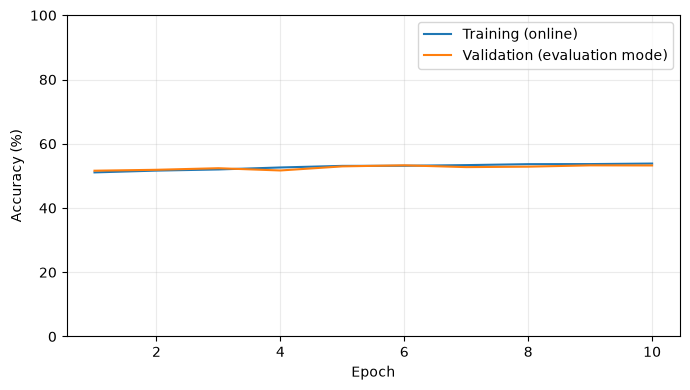

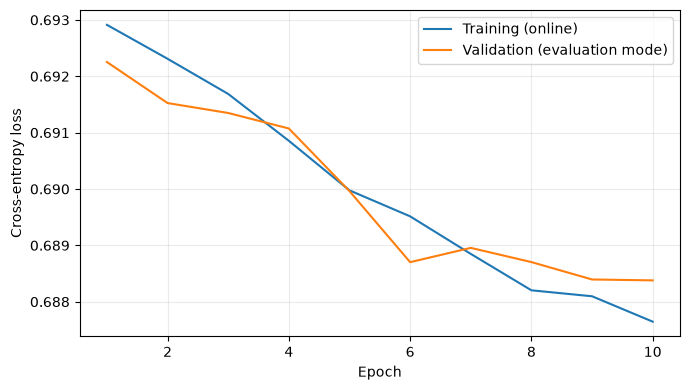

{
  "records": 3000,
  "loss": 0.6886862383683523,
  "accuracy": 0.5373333333333333,
  "balanced_accuracy": 0.5324249452017559,
  "macro_f1": 0.5230021994134897,
  "roc_auc": 0.5496734349412379,
  "confusion_matrix": [
    [
      546,
      907
    ],
    [
      481,
      1066
    ]
  ],
  "prediction_counts": [
    1027,
    1973
  ],
  "single_class_predictions": false,
  "classification_report": {
    "PeakBelow83": {
      "precision": 0.5316455696202531,
      "recall": 0.37577426015141085,
      "f1-score": 0.4403225806451613,
      "support": 1453.0
    },
    "PeakAtOrAbove83": {
      "precision": 0.5402939685757729,
      "recall": 0.6890756302521008,
      "f1-score": 0.6056818181818182,
      "support": 1547.0
    },
    "accuracy": 0.5373333333333333,
    "macro avg": {
      "precision": 0.535969769098013,
      "recall": 0.5324249452017559,
      "f1-score": 0.5230021994134897,
      "support": 3000.0
    },
    "weighted avg": {
      "precision": 0.5361052606816495,

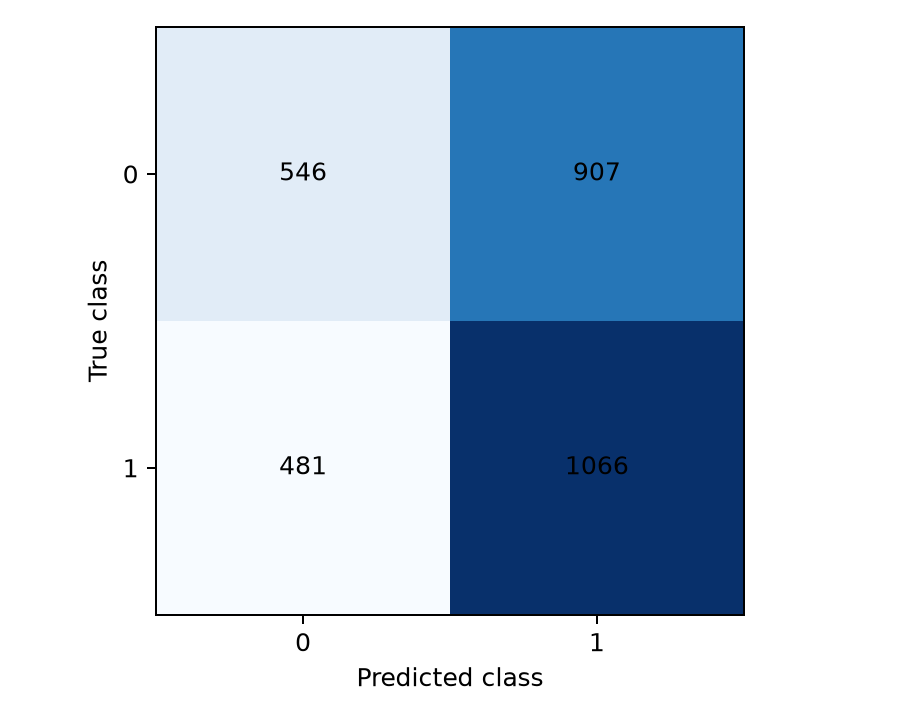

In [16]:
if "result" in globals():
    print("Results:", result["folder"])
    plot_history(result["folder"], show=True)
    if result["test_metrics"] is not None:
        print(json.dumps(result["test_metrics"], indent=2))
        display(Image.open(result["folder"] / "test_confusion_matrix.png"))
